In [9]:
# simulate_librispeech_pyroom_4mic_3src.py
# ------------------------------------------------------------
# 4-mic / 3-source / no-reverb / LibriSpeech FFT dominant-band
# simulation with pyroomacoustics + optional MUSIC baseline
#
# pip install pyroomacoustics soundfile scipy matplotlib numpy
# ------------------------------------------------------------

import math
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt

from scipy.signal import stft, resample_poly, find_peaks
from scipy.fft import rfft, irfft, rfftfreq
import pyroomacoustics as pra


# ------------------------------------------------------------
# Global config
# ------------------------------------------------------------
FS = 16000
C = 343.0
DURATION_SEC = 3.0

# 3D MUSIC scan grid
AZ_GRID_DEG = np.linspace(-180.0, 180.0, 361)
EL_GRID_DEG = np.linspace(-60.0, 60.0, 121)

# Replace with your own LibriSpeech wav paths
LIBRISPEECH_FILES = [
    "C:/26'음향학회 춘계학술대회/male26.flac",
    "C:/26'음향학회 춘계학술대회/female19.flac",
    "C:/26'음향학회 춘계학술대회/female8975.flac",
]

# 3 sources around the array (broadside = 0 deg, left negative, right positive)
SOURCE_AZIMUTH_DEG = np.array([-35.0, 5.0, 40.0])
SOURCE_ELEVATION_DEG = np.array([0,0,0])
SOURCE_DISTANCES_M = np.array([2.5, 2.8, 3.2])  # far enough for approximate far-field

ARRAY_CENTER = np.array([0.0, 0.0, 1.5])

# Array comparison setting
COMPARE_MODE = "same_baseline"
# options:
#   "same_spacing"
#   "same_baseline"

BASE_VALUE_M = 0.08
# if same_spacing:
#   linear adjacent spacing = 0.08 m
#   tetra edge length       = 0.08 m
#
# if same_baseline:
#   linear max baseline     = 0.08 m
#   tetra max baseline      = 0.08 m

# Frequency band selection
SEARCH_FMIN_HZ = 300.0
SEARCH_FMAX_HZ = 3400.0
BANDWIDTH_HZ = 150.0     # retained band width around selected center frequency
STFT_NFFT = 1024
STFT_HOP = 256

# MUSIC
N_SOURCES = 3
AZ_GRID_DEG = np.linspace(-180.0, 180.0, 361)
EL_GRID_DEG = np.linspace(-60.0, 60.0, 121)

In [10]:
# ------------------------------------------------------------
# Audio helpers
# ------------------------------------------------------------
def read_audio_mono_resample(path: str, target_fs: int) -> np.ndarray:
    x, fs = sf.read(path)
    if x.ndim > 1:
        x = np.mean(x, axis=1)

    x = x.astype(np.float64)
    if fs != target_fs:
        g = math.gcd(fs, target_fs)
        up = target_fs // g
        down = fs // g
        x = resample_poly(x, up, down)

    x = x - np.mean(x)
    peak = np.max(np.abs(x)) + 1e-12
    x = x / peak
    return x


def center_crop_or_pad(x: np.ndarray, target_len: int) -> np.ndarray:
    if len(x) >= target_len:
        start = (len(x) - target_len) // 2
        return x[start:start + target_len].copy()

    y = np.zeros(target_len, dtype=np.float64)
    y[:len(x)] = x
    return y


def average_speech_spectrum(
    x: np.ndarray,
    fs: int,
    n_fft: int = 2048,
    hop: int = 512,
) -> tuple[np.ndarray, np.ndarray]:
    f, _, Z = stft(
        x,
        fs=fs,
        window="hann",
        nperseg=n_fft,
        noverlap=n_fft - hop,
        boundary=None,
        padded=False,
    )

    mag = np.abs(Z)
    frame_energy = np.mean(mag**2, axis=0)

    # Use only higher-energy frames to avoid silence dominating the peak search
    thr = np.percentile(frame_energy, 40.0)
    valid = frame_energy > thr
    if not np.any(valid):
        valid = np.ones_like(frame_energy, dtype=bool)

    avg_mag = np.mean(mag[:, valid], axis=1)
    return f, avg_mag


def choose_common_dominant_band(
    signals: list[np.ndarray],
    fs: int,
    fmin_hz: float,
    fmax_hz: float,
) -> float:
    """
    Choose ONE common dominant center frequency across all utterances.
    This is better than per-source peak if you want a narrowband DOA model.
    """
    stacked = None
    freqs = None

    for x in signals:
        f, avg_mag = average_speech_spectrum(x, fs=fs)
        avg_mag = avg_mag / (np.max(avg_mag) + 1e-12)

        if stacked is None:
            stacked = avg_mag
            freqs = f
        else:
            stacked += avg_mag

    mask = (freqs >= fmin_hz) & (freqs <= fmax_hz)
    if not np.any(mask):
        raise ValueError("No FFT bins inside the search range.")

    f_sel = freqs[mask]
    a_sel = stacked[mask]
    center_hz = f_sel[np.argmax(a_sel)]
    return float(center_hz)


def fft_keep_only_band(
    x: np.ndarray,
    fs: int,
    center_hz: float,
    bandwidth_hz: float,
) -> np.ndarray:
    """
    Keep only a narrow FFT band around center_hz, then inverse FFT.
    """
    n = len(x)
    X = rfft(x)
    f = rfftfreq(n, d=1.0 / fs)

    half_bw = bandwidth_hz / 2.0
    mask = (f >= center_hz - half_bw) & (f <= center_hz + half_bw)

    Y = np.zeros_like(X)
    Y[mask] = X[mask]
    y = irfft(Y, n=n)

    y = y - np.mean(y)
    y = y / (np.max(np.abs(y)) + 1e-12)
    return y.astype(np.float64)

Selected common center frequency (Hz): 570.31
COMPARE_MODE = same_baseline
linear adjacent spacing = 0.026667 m
linear max baseline     = 0.080000 m
tetra edge length       = 0.080000 m
tetra max baseline      = 0.080000 m
[Linear ULA (4 mics)]
Actual STFT bin frequency (Hz): 562.5
Mic signal shape:              (4, 48232)
Bin snapshot matrix shape:     (4, 185)
True DOAs (az, el) deg:
  (-35.00,   0.00)
  (  5.00,   0.00)
  ( 40.00,   0.00)
Estimated DOAs from 3D MUSIC (az, el) deg:
  (163.00,  29.00)  score=1.0000
  (-163.00,  29.00)  score=1.0000
  (163.00, -29.00)  score=1.0000
[Tetrahedral array (4 mics)]
Actual STFT bin frequency (Hz): 562.5
Mic signal shape:              (4, 48234)
Bin snapshot matrix shape:     (4, 185)
True DOAs (az, el) deg:
  (-35.00,   0.00)
  (  5.00,   0.00)
  ( 40.00,   0.00)
Estimated DOAs from 3D MUSIC (az, el) deg:
  (-176.00,   0.00)  score=1.0000
  ( -7.00,   1.00)  score=0.0061
  (180.00,   0.00)  score=0.0035


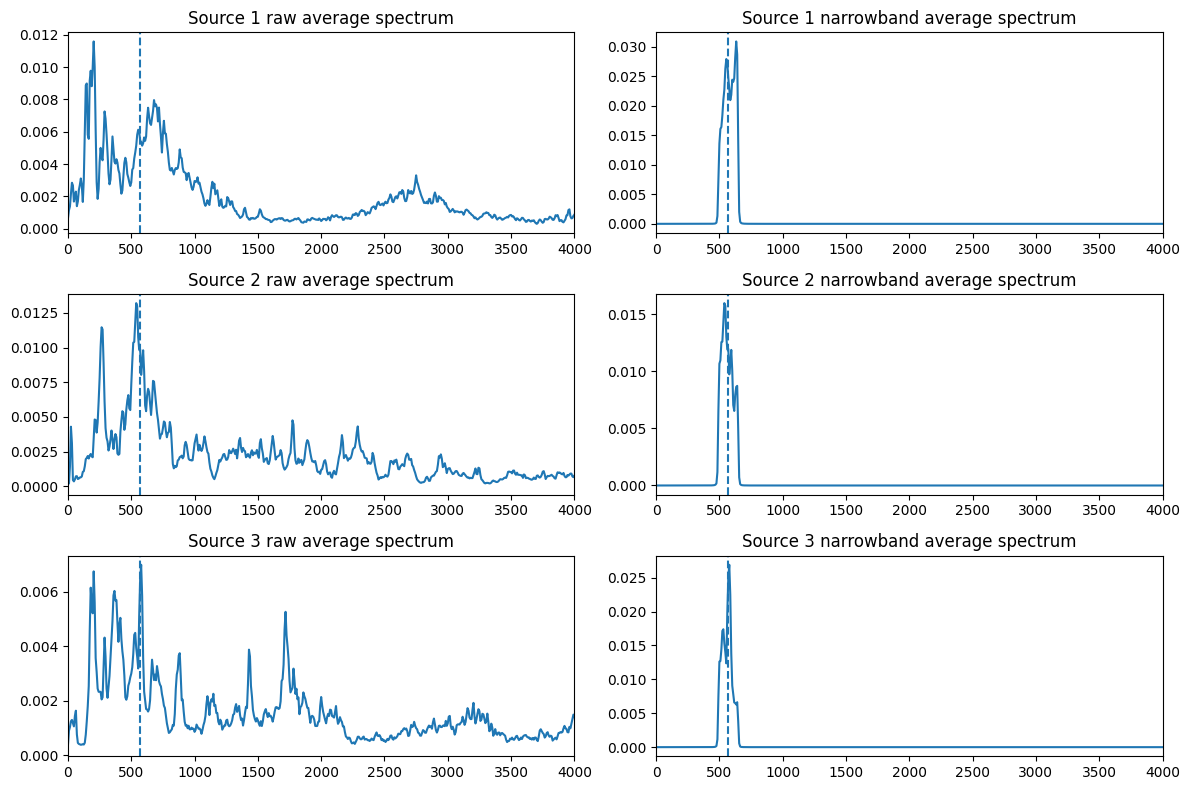

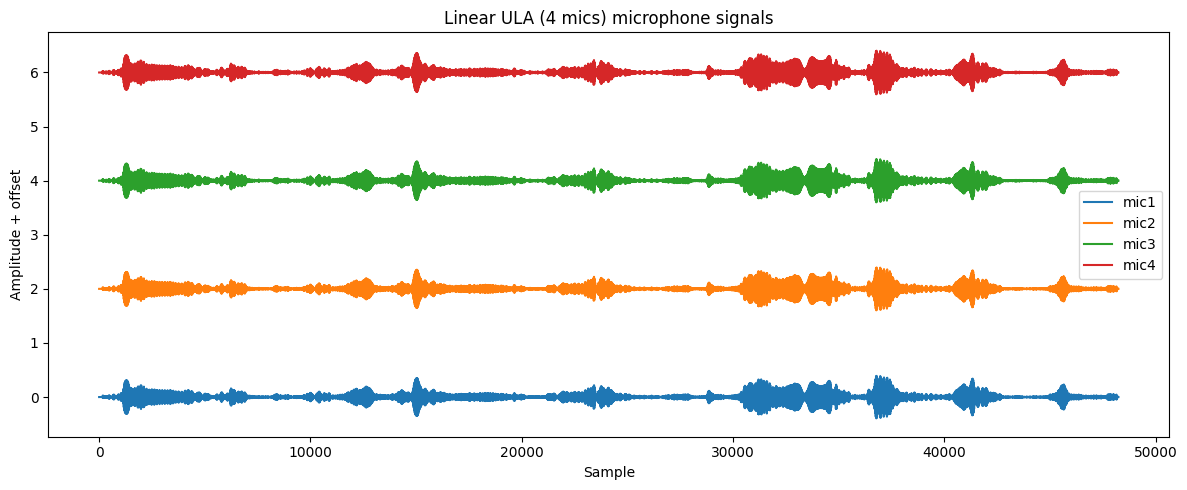

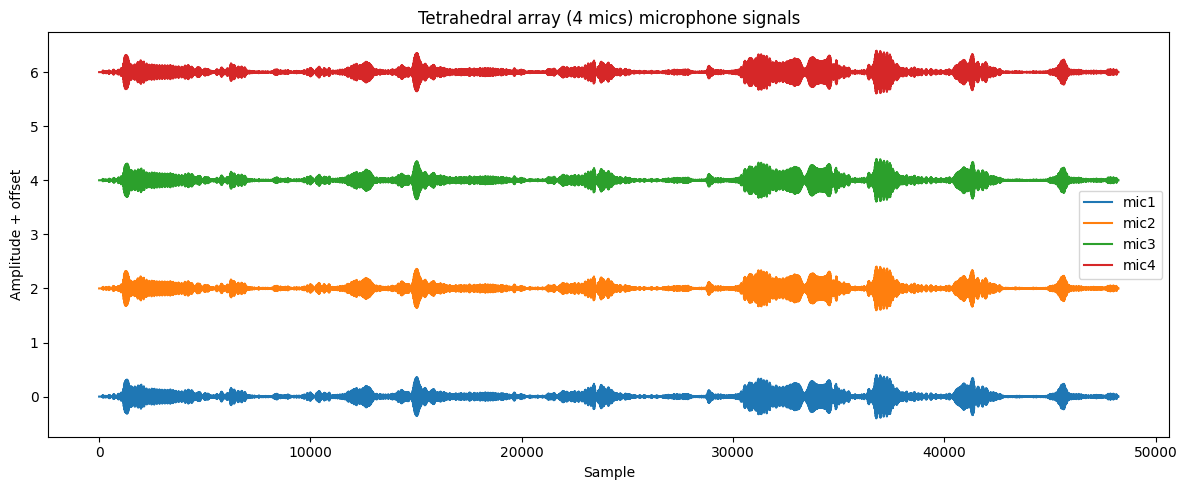

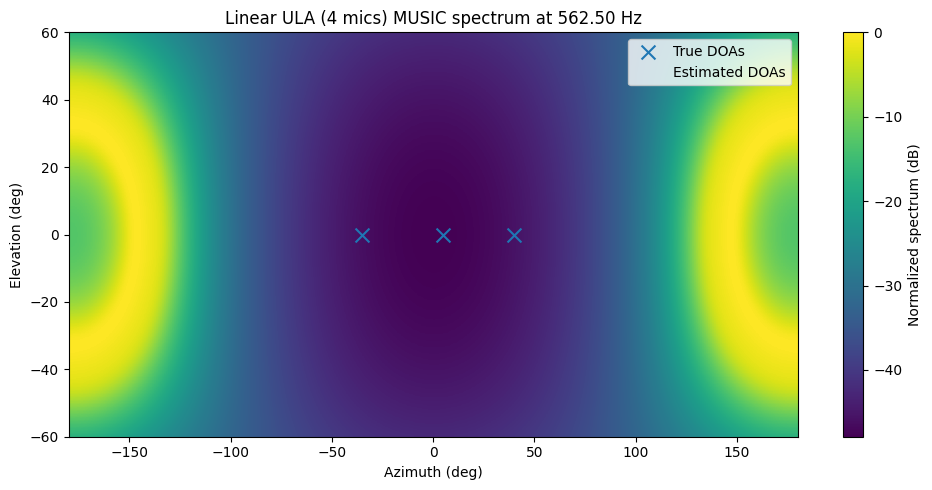

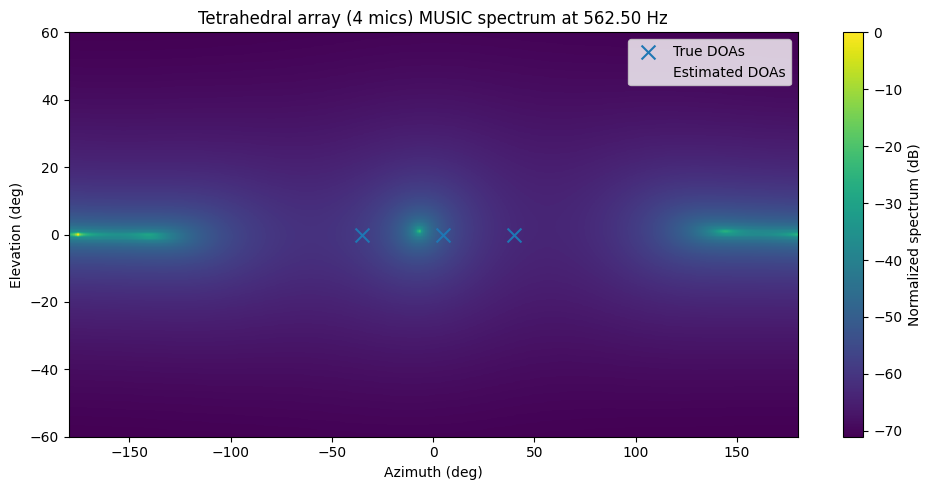

In [11]:
# ------------------------------------------------------------
# Geometry helpers
# ------------------------------------------------------------
from scipy.ndimage import maximum_filter
def make_linear_ula(center_xyz: np.ndarray, spacing_m: float) -> np.ndarray:
    """
    4-mic uniform linear array centered at center_xyz.
    Adjacent spacing = spacing_m
    Max baseline = 3 * spacing_m
    Returns shape (3, 4)
    """
    offsets = np.array([-1.5, -0.5, 0.5, 1.5]) * spacing_m
    x = center_xyz[0] + offsets
    y = np.full(4, center_xyz[1], dtype=np.float64)
    z = np.full(4, center_xyz[2], dtype=np.float64)
    return np.vstack([x, y, z])


def make_regular_tetrahedron_array(center_xyz: np.ndarray, edge_m: float) -> np.ndarray:
    """
    Regular tetrahedron centered at center_xyz.
    All pairwise distances = edge_m
    Returns shape (3, 4)
    """
    verts = np.array([
        [ 1.0,  1.0,  1.0],
        [ 1.0, -1.0, -1.0],
        [-1.0,  1.0, -1.0],
        [-1.0, -1.0,  1.0],
    ])
    scale = edge_m / (2.0 * np.sqrt(2.0))
    verts = scale * verts + center_xyz[None, :]
    return verts.T


def build_arrays_for_comparison(
    center_xyz: np.ndarray,
    mode: str,
    base_value_m: float,
) -> tuple[np.ndarray, np.ndarray, float, float]:
    """
    mode == "same_spacing":
        linear adjacent spacing = tetra edge length = base_value_m

    mode == "same_baseline":
        linear max baseline = tetra max baseline = base_value_m
        -> linear spacing = base_value_m / 3
        -> tetra edge     = base_value_m
    """
    if mode == "same_spacing":
        linear_spacing = base_value_m
        tetra_edge = base_value_m

    elif mode == "same_baseline":
        tetra_edge = base_value_m
        linear_spacing = base_value_m / 3.0

    else:
        raise ValueError("mode must be 'same_spacing' or 'same_baseline'")

    linear_mics = make_linear_ula(center_xyz, linear_spacing)
    tetra_mics = make_regular_tetrahedron_array(center_xyz, tetra_edge)

    return linear_mics, tetra_mics, linear_spacing, tetra_edge


def sph_to_cart(center_xyz: np.ndarray, az_deg: float, el_deg: float, r: float) -> np.ndarray:
    """
    Standard spherical convention:
      azimuth: xy-plane from +x toward +y
      elevation: from xy-plane toward +z
    """
    az = np.deg2rad(az_deg)
    el = np.deg2rad(el_deg)

    x = center_xyz[0] + r * np.cos(el) * np.cos(az)
    y = center_xyz[1] + r * np.cos(el) * np.sin(az)
    z = center_xyz[2] + r * np.sin(el)
    return np.array([x, y, z], dtype=np.float64)


def unit_direction_from_az_el(az_deg: float, el_deg: float) -> np.ndarray:
    az = np.deg2rad(az_deg)
    el = np.deg2rad(el_deg)
    return np.array([
        np.cos(el) * np.cos(az),
        np.cos(el) * np.sin(az),
        np.sin(el),
    ], dtype=np.float64)


# ------------------------------------------------------------
# STFT / covariance
# ------------------------------------------------------------
def multichannel_stft(
    y_mics: np.ndarray,
    fs: int,
    n_fft: int,
    hop: int,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    Z_all = []
    f_ref = None
    t_ref = None

    for m in range(y_mics.shape[0]):
        f, t, Z = stft(
            y_mics[m],
            fs=fs,
            window="hann",
            nperseg=n_fft,
            noverlap=n_fft - hop,
            boundary=None,
            padded=False,
        )
        Z_all.append(Z)
        if f_ref is None:
            f_ref = f
            t_ref = t

    Z_all = np.stack(Z_all, axis=0)  # M x F x T
    return f_ref, t_ref, Z_all


def extract_frequency_bin_snapshots(
    y_mics: np.ndarray,
    fs: int,
    target_hz: float,
    n_fft: int,
    hop: int,
) -> tuple[float, np.ndarray]:
    f, _, Z = multichannel_stft(y_mics, fs, n_fft=n_fft, hop=hop)
    k = int(np.argmin(np.abs(f - target_hz)))
    X_bin = Z[:, k, :]
    return float(f[k]), X_bin


def sample_covariance(X: np.ndarray) -> np.ndarray:
    return (X @ X.conj().T) / X.shape[1]


# ------------------------------------------------------------
# 3D MUSIC
# ------------------------------------------------------------
def steering_vector_3d(
    mic_positions_xyz: np.ndarray,
    array_center_xyz: np.ndarray,
    freq_hz: float,
    az_deg: float,
    el_deg: float,
    c: float = 343.0,
) -> np.ndarray:
    """
    Far-field narrowband steering vector for arbitrary 3D array.
    """
    u = unit_direction_from_az_el(az_deg, el_deg)
    rel = mic_positions_xyz - array_center_xyz[:, None]
    phase = -2.0j * np.pi * freq_hz / c * (rel.T @ u)
    return np.exp(phase)[:, None]


def music_spectrum_3d(
    R: np.ndarray,
    mic_positions_xyz: np.ndarray,
    array_center_xyz: np.ndarray,
    freq_hz: float,
    n_sources: int,
    az_grid_deg: np.ndarray,
    el_grid_deg: np.ndarray,
    c: float = 343.0,
) -> np.ndarray:
    eigvals, eigvecs = np.linalg.eigh(R)
    order = np.argsort(eigvals)[::-1]
    eigvecs = eigvecs[:, order]

    En = eigvecs[:, n_sources:]
    P = np.zeros((len(el_grid_deg), len(az_grid_deg)), dtype=np.float64)

    for i_el, el in enumerate(el_grid_deg):
        for i_az, az in enumerate(az_grid_deg):
            a = steering_vector_3d(
                mic_positions_xyz=mic_positions_xyz,
                array_center_xyz=array_center_xyz,
                freq_hz=freq_hz,
                az_deg=az,
                el_deg=el,
                c=c,
            )
            denom = (a.conj().T @ En @ En.conj().T @ a).squeeze()
            P[i_el, i_az] = 1.0 / (np.abs(denom) + 1e-12)

    P = P / (np.max(P) + 1e-12)
    return P


def estimate_music_peaks_3d(
    P: np.ndarray,
    az_grid_deg: np.ndarray,
    el_grid_deg: np.ndarray,
    n_sources: int,
    neighborhood_az_bins: int = 9,
    neighborhood_el_bins: int = 7,
) -> list[tuple[float, float, float]]:
    size = (neighborhood_el_bins, neighborhood_az_bins)
    Pmax = maximum_filter(P, size=size, mode="nearest")
    peak_mask = (P == Pmax)

    peak_indices = np.argwhere(peak_mask)
    if len(peak_indices) == 0:
        return []

    peak_values = np.array([P[i, j] for i, j in peak_indices])
    order = np.argsort(peak_values)[::-1]

    results = []
    used = []

    for idx in order:
        i_el, i_az = peak_indices[idx]
        val = peak_values[idx]

        az = az_grid_deg[i_az]
        el = el_grid_deg[i_el]

        too_close = False
        for prev_az, prev_el, _ in used:
            if abs(az - prev_az) < 6.0 and abs(el - prev_el) < 6.0:
                too_close = True
                break
        if too_close:
            continue

        results.append((float(az), float(el), float(val)))
        used.append((float(az), float(el), float(val)))

        if len(results) >= n_sources:
            break

    return results


# ------------------------------------------------------------
# Simulation / evaluation helpers
# ------------------------------------------------------------
def simulate_array_signals(
    mic_locs: np.ndarray,
    source_positions: list[np.ndarray],
    source_signals: list[np.ndarray],
    fs: int,
) -> np.ndarray:
    room = pra.AnechoicRoom(fs=fs, dim=3)
    room.add_microphone_array(mic_locs)

    for pos, sig in zip(source_positions, source_signals):
        room.add_source(pos, signal=sig)

    room.simulate()
    return room.mic_array.signals


def run_music_pipeline_for_array(
    array_name: str,
    mic_locs: np.ndarray,
    source_positions: list[np.ndarray],
    source_signals: list[np.ndarray],
    center_hz: float,
) -> dict:
    y_mics = simulate_array_signals(
        mic_locs=mic_locs,
        source_positions=source_positions,
        source_signals=source_signals,
        fs=FS,
    )

    chosen_bin_hz, X_bin = extract_frequency_bin_snapshots(
        y_mics=y_mics,
        fs=FS,
        target_hz=center_hz,
        n_fft=STFT_NFFT,
        hop=STFT_HOP,
    )

    R = sample_covariance(X_bin)

    P = music_spectrum_3d(
        R=R,
        mic_positions_xyz=mic_locs,
        array_center_xyz=ARRAY_CENTER,
        freq_hz=chosen_bin_hz,
        n_sources=N_SOURCES,
        az_grid_deg=AZ_GRID_DEG,
        el_grid_deg=EL_GRID_DEG,
        c=C,
    )

    peaks = estimate_music_peaks_3d(
        P=P,
        az_grid_deg=AZ_GRID_DEG,
        el_grid_deg=EL_GRID_DEG,
        n_sources=N_SOURCES,
    )

    return {
        "array_name": array_name,
        "mic_locs": mic_locs,
        "y_mics": y_mics,
        "chosen_bin_hz": chosen_bin_hz,
        "X_bin": X_bin,
        "R": R,
        "P": P,
        "peaks": peaks,
    }


def print_array_summary(
    result: dict,
    true_az_deg: np.ndarray,
    true_el_deg: np.ndarray,
):
    print("=" * 70)
    print(f"[{result['array_name']}]")
    print("Actual STFT bin frequency (Hz):", round(result["chosen_bin_hz"], 2))
    print("Mic signal shape:             ", result["y_mics"].shape)
    print("Bin snapshot matrix shape:    ", result["X_bin"].shape)

    print("True DOAs (az, el) deg:")
    for az, el in zip(true_az_deg, true_el_deg):
        print(f"  ({az:6.2f}, {el:6.2f})")

    print("Estimated DOAs from 3D MUSIC (az, el) deg:")
    for az, el, val in result["peaks"]:
        print(f"  ({az:6.2f}, {el:6.2f})  score={val:.4f}")
    print("=" * 70)


def plot_music_heatmap(
    result: dict,
    true_az_deg: np.ndarray,
    true_el_deg: np.ndarray,
):
    P = result["P"]
    peaks = result["peaks"]

    plt.figure(figsize=(10, 5))
    plt.imshow(
        10.0 * np.log10(P + 1e-12),
        aspect="auto",
        origin="lower",
        extent=[AZ_GRID_DEG[0], AZ_GRID_DEG[-1], EL_GRID_DEG[0], EL_GRID_DEG[-1]],
    )
    plt.colorbar(label="Normalized spectrum (dB)")
    plt.xlabel("Azimuth (deg)")
    plt.ylabel("Elevation (deg)")
    plt.title(f"{result['array_name']} MUSIC spectrum at {result['chosen_bin_hz']:.2f} Hz")

    plt.scatter(
        true_az_deg,
        true_el_deg,
        marker="x",
        s=100,
        label="True DOAs",
    )

    if len(peaks) > 0:
        est_az = [p[0] for p in peaks]
        est_el = [p[1] for p in peaks]
        plt.scatter(
            est_az,
            est_el,
            marker="o",
            s=60,
            facecolors="none",
            label="Estimated DOAs",
        )

    plt.legend()
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# Main
# ------------------------------------------------------------
def main():
    assert len(LIBRISPEECH_FILES) == 3, "Please provide exactly 3 source files."

    target_len = int(FS * DURATION_SEC)

    # 1) Load sources
    raw_sources = []
    for path in LIBRISPEECH_FILES:
        x = read_audio_mono_resample(path, FS)
        x = center_crop_or_pad(x, target_len)
        raw_sources.append(x)

    # 2) Choose common dominant band only once
    center_hz = choose_common_dominant_band(
        raw_sources,
        fs=FS,
        fmin_hz=SEARCH_FMIN_HZ,
        fmax_hz=SEARCH_FMAX_HZ,
    )

    # 3) Keep only narrow band only once
    narrow_sources = [
        fft_keep_only_band(x, fs=FS, center_hz=center_hz, bandwidth_hz=BANDWIDTH_HZ)
        for x in raw_sources
    ]

    print("Selected common center frequency (Hz):", round(center_hz, 2))

    # 4) Build both arrays with a shared comparison rule
    linear_mics, tetra_mics, linear_spacing, tetra_edge = build_arrays_for_comparison(
        center_xyz=ARRAY_CENTER,
        mode=COMPARE_MODE,
        base_value_m=BASE_VALUE_M,
    )

    print(f"COMPARE_MODE = {COMPARE_MODE}")
    print(f"linear adjacent spacing = {linear_spacing:.6f} m")
    print(f"linear max baseline     = {3.0 * linear_spacing:.6f} m")
    print(f"tetra edge length       = {tetra_edge:.6f} m")
    print(f"tetra max baseline      = {tetra_edge:.6f} m")

    # 5) Create exactly the same source positions for both arrays
    true_positions = []
    for az_deg, el_deg, dist_m in zip(
        SOURCE_AZIMUTH_DEG,
        SOURCE_ELEVATION_DEG,
        SOURCE_DISTANCES_M,
    ):
        src_pos = sph_to_cart(ARRAY_CENTER, az_deg, el_deg, dist_m)
        true_positions.append(src_pos)

    # 6) Run the same pipeline for both arrays
    linear_result = run_music_pipeline_for_array(
        array_name="Linear ULA (4 mics)",
        mic_locs=linear_mics,
        source_positions=true_positions,
        source_signals=narrow_sources,
        center_hz=center_hz,
    )

    tetra_result = run_music_pipeline_for_array(
        array_name="Tetrahedral array (4 mics)",
        mic_locs=tetra_mics,
        source_positions=true_positions,
        source_signals=narrow_sources,
        center_hz=center_hz,
    )

    # 7) Print summary
    print_array_summary(
        linear_result,
        true_az_deg=SOURCE_AZIMUTH_DEG,
        true_el_deg=SOURCE_ELEVATION_DEG,
    )

    print_array_summary(
        tetra_result,
        true_az_deg=SOURCE_AZIMUTH_DEG,
        true_el_deg=SOURCE_ELEVATION_DEG,
    )

    # 8) Plot average spectrum before/after narrowband extraction
    fig, axes = plt.subplots(3, 2, figsize=(12, 8))
    for i, (x_raw, x_nb) in enumerate(zip(raw_sources, narrow_sources)):
        f1, s1 = average_speech_spectrum(x_raw, FS)
        f2, s2 = average_speech_spectrum(x_nb, FS)

        axes[i, 0].plot(f1, s1)
        axes[i, 0].axvline(center_hz, linestyle="--")
        axes[i, 0].set_xlim(0, 4000)
        axes[i, 0].set_title(f"Source {i+1} raw average spectrum")

        axes[i, 1].plot(f2, s2)
        axes[i, 1].axvline(center_hz, linestyle="--")
        axes[i, 1].set_xlim(0, 4000)
        axes[i, 1].set_title(f"Source {i+1} narrowband average spectrum")

    plt.tight_layout()
    plt.show()

    # 9) Plot mic signals for each array
    for result in [linear_result, tetra_result]:
        plt.figure(figsize=(12, 5))
        for m in range(result["y_mics"].shape[0]):
            plt.plot(result["y_mics"][m] + 2.0 * m, label=f"mic{m+1}")
        plt.title(f"{result['array_name']} microphone signals")
        plt.xlabel("Sample")
        plt.ylabel("Amplitude + offset")
        plt.legend()
        plt.tight_layout()
        plt.show()

    # 10) Plot MUSIC heatmaps
    plot_music_heatmap(
        linear_result,
        true_az_deg=SOURCE_AZIMUTH_DEG,
        true_el_deg=SOURCE_ELEVATION_DEG,
    )

    plot_music_heatmap(
        tetra_result,
        true_az_deg=SOURCE_AZIMUTH_DEG,
        true_el_deg=SOURCE_ELEVATION_DEG,
    )


if __name__ == "__main__":
    main()

In [12]:
# ------------------------------------------------------------
# Linear-array 1D MUSIC (azimuth only)
# ------------------------------------------------------------
def steering_vector_linear_azimuth(
    mic_positions_xyz: np.ndarray,
    array_center_xyz: np.ndarray,
    freq_hz: float,
    az_deg: float,
    c: float = 343.0,
) -> np.ndarray:
    """
    Linear ULA on x-axis, azimuth-only steering vector.
    Elevation is assumed to be 0 deg.
    """
    az = np.deg2rad(az_deg)
    x_rel = mic_positions_xyz[0, :] - array_center_xyz[0]
    phase = -2.0j * np.pi * freq_hz / c * x_rel * np.sin(az)
    return np.exp(phase)[:, None]


def music_spectrum_linear_1d(
    R: np.ndarray,
    mic_positions_xyz: np.ndarray,
    array_center_xyz: np.ndarray,
    freq_hz: float,
    n_sources: int,
    az_grid_deg: np.ndarray,
    c: float = 343.0,
) -> np.ndarray:
    eigvals, eigvecs = np.linalg.eigh(R)
    order = np.argsort(eigvals)[::-1]
    eigvecs = eigvecs[:, order]

    En = eigvecs[:, n_sources:]
    P = np.zeros(len(az_grid_deg), dtype=np.float64)

    for i, az in enumerate(az_grid_deg):
        a = steering_vector_linear_azimuth(
            mic_positions_xyz=mic_positions_xyz,
            array_center_xyz=array_center_xyz,
            freq_hz=freq_hz,
            az_deg=az,
            c=c,
        )
        denom = (a.conj().T @ En @ En.conj().T @ a).squeeze()
        P[i] = 1.0 / (np.abs(denom) + 1e-12)

    P = P / (np.max(P) + 1e-12)
    return P


def estimate_music_peaks_1d(
    P: np.ndarray,
    az_grid_deg: np.ndarray,
    n_sources: int,
    min_peak_distance_deg: float = 5.0,
) -> list[tuple[float, float]]:
    step_deg = float(np.abs(az_grid_deg[1] - az_grid_deg[0]))
    min_distance_bins = max(1, int(min_peak_distance_deg / step_deg))

    peaks, _ = find_peaks(P, distance=min_distance_bins)
    if len(peaks) == 0:
        return []

    peak_vals = P[peaks]
    order = np.argsort(peak_vals)[::-1]
    chosen = peaks[order[:n_sources]]

    results = [(float(az_grid_deg[i]), float(P[i])) for i in chosen]
    results.sort(key=lambda x: x[0])
    return results

In [14]:
# ------------------------------------------------------------
# RMSE helpers
# ------------------------------------------------------------
def azimuth_rmse_deg(
    true_az_deg: np.ndarray,
    est_az_deg: np.ndarray,
) -> float:
    """
    One-trial azimuth RMSE after sorting.
    Assumes same number of sources.
    """
    true_az = np.sort(np.asarray(true_az_deg, dtype=np.float64))
    est_az = np.sort(np.asarray(est_az_deg, dtype=np.float64))

    if len(true_az) != len(est_az):
        raise ValueError(f"RMSE source count mismatch: true={len(true_az)}, est={len(est_az)}")

    return float(np.sqrt(np.mean((est_az - true_az) ** 2)))

In [ ]:
def main():
    assert len(LIBRISPEECH_FILES) == 3, "Please provide exactly 3 source files."

    target_len = int(FS * DURATION_SEC)

    # 1) Load sources
    raw_sources = []
    for path in LIBRISPEECH_FILES:
        x = read_audio_mono_resample(path, FS)
        x = center_crop_or_pad(x, target_len)
        raw_sources.append(x)

    # 2) Choose common dominant band once
    center_hz = choose_common_dominant_band(
        raw_sources,
        fs=FS,
        fmin_hz=SEARCH_FMIN_HZ,
        fmax_hz=SEARCH_FMAX_HZ,
    )

    # 3) Keep only narrow band once
    narrow_sources = [
        fft_keep_only_band(x, fs=FS, center_hz=center_hz, bandwidth_hz=BANDWIDTH_HZ)
        for x in raw_sources
    ]

    print("Selected common center frequency (Hz):", round(center_hz, 2))

    # 4) Build both arrays
    linear_mics, tetra_mics, linear_spacing, tetra_edge = build_arrays_for_comparison(
        center_xyz=ARRAY_CENTER,
        mode=COMPARE_MODE,
        base_value_m=BASE_VALUE_M,
    )

    print(f"COMPARE_MODE = {COMPARE_MODE}")
    print(f"linear adjacent spacing = {linear_spacing:.6f} m")
    print(f"linear max baseline     = {3.0 * linear_spacing:.6f} m")
    print(f"tetra edge length       = {tetra_edge:.6f} m")
    print(f"tetra max baseline      = {tetra_edge:.6f} m")

    # 5) Common source positions
    true_positions = []
    for az_deg, el_deg, dist_m in zip(
        SOURCE_AZIMUTH_DEG,
        SOURCE_ELEVATION_DEG,
        SOURCE_DISTANCES_M,
    ):
        src_pos = sph_to_cart(ARRAY_CENTER, az_deg, el_deg, dist_m)
        true_positions.append(src_pos)

    # 6) Run separately
    linear_result = run_linear_music_pipeline(  
        mic_locs=linear_mics,
        source_positions=true_positions,
        source_signals=narrow_sources,
        center_hz=center_hz,
    )

    tetra_result = run_tetra_music_pipeline(
        mic_locs=tetra_mics,
        source_positions=true_positions,
        source_signals=narrow_sources,
        center_hz=center_hz,
    )

    # 7) Azimuth RMSE
    linear_rmse = azimuth_rmse_deg(
        true_az_deg=SOURCE_AZIMUTH_DEG,
        est_az_deg=linear_result["est_az_deg"],
    )

    tetra_rmse = azimuth_rmse_deg(
        true_az_deg=SOURCE_AZIMUTH_DEG,
        est_az_deg=tetra_result["est_az_deg"],
    )

    print("=" * 70)
    print("True azimuths (deg):", np.sort(SOURCE_AZIMUTH_DEG))
    print("Linear estimated azimuths (deg):", np.sort(linear_result["est_az_deg"]))
    print("Tetra  estimated azimuths (deg):", np.sort(tetra_result["est_az_deg"]))
    print(f"Linear azimuth RMSE (deg): {linear_rmse:.4f}")
    print(f"Tetra  azimuth RMSE (deg): {tetra_rmse:.4f}")
    print("=" * 70)

In [16]:
def main():
    assert len(LIBRISPEECH_FILES) == 3, "Please provide exactly 3 source files."

    target_len = int(FS * DURATION_SEC)

    # 1) Load sources
    raw_sources = []
    for path in LIBRISPEECH_FILES:
        x = read_audio_mono_resample(path, FS)
        x = center_crop_or_pad(x, target_len)
        raw_sources.append(x)

    # 2) Choose common dominant band once
    center_hz = choose_common_dominant_band(
        raw_sources,
        fs=FS,
        fmin_hz=SEARCH_FMIN_HZ,
        fmax_hz=SEARCH_FMAX_HZ,
    )

    # 3) Keep only narrow band once
    narrow_sources = [
        fft_keep_only_band(x, fs=FS, center_hz=center_hz, bandwidth_hz=BANDWIDTH_HZ)
        for x in raw_sources
    ]

    print("Selected common center frequency (Hz):", round(center_hz, 2))

    # 4) Build both arrays
    linear_mics, tetra_mics, linear_spacing, tetra_edge = build_arrays_for_comparison(
        center_xyz=ARRAY_CENTER,
        mode=COMPARE_MODE,
        base_value_m=BASE_VALUE_M,
    )

    print(f"COMPARE_MODE = {COMPARE_MODE}")
    print(f"linear adjacent spacing = {linear_spacing:.6f} m")
    print(f"linear max baseline     = {3.0 * linear_spacing:.6f} m")
    print(f"tetra edge length       = {tetra_edge:.6f} m")
    print(f"tetra max baseline      = {tetra_edge:.6f} m")

    # 5) Common source positions
    true_positions = []
    for az_deg, el_deg, dist_m in zip(
        SOURCE_AZIMUTH_DEG,
        SOURCE_ELEVATION_DEG,
        SOURCE_DISTANCES_M,
    ):
        src_pos = sph_to_cart(ARRAY_CENTER, az_deg, el_deg, dist_m)
        true_positions.append(src_pos)

    # 6) Run separately
    linear_result = run_linear_music_pipeline(
        mic_locs=linear_mics,
        source_positions=true_positions,
        source_signals=narrow_sources,
        center_hz=center_hz,
    )

    tetra_result = run_tetra_music_pipeline(
        mic_locs=tetra_mics,
        source_positions=true_positions,
        source_signals=narrow_sources,
        center_hz=center_hz,
    )

    # 7) Azimuth RMSE
    linear_rmse = azimuth_rmse_deg(
        true_az_deg=SOURCE_AZIMUTH_DEG,
        est_az_deg=linear_result["est_az_deg"],
    )

    tetra_rmse = azimuth_rmse_deg(
        true_az_deg=SOURCE_AZIMUTH_DEG,
        est_az_deg=tetra_result["est_az_deg"],
    )

    print("=" * 70)
    print("True azimuths (deg):", np.sort(SOURCE_AZIMUTH_DEG))
    print("Linear estimated azimuths (deg):", np.sort(linear_result["est_az_deg"]))
    print("Tetra  estimated azimuths (deg):", np.sort(tetra_result["est_az_deg"]))
    print(f"Linear azimuth RMSE (deg): {linear_rmse:.4f}")
    print(f"Tetra  azimuth RMSE (deg): {tetra_rmse:.4f}")
    print("=" * 70)